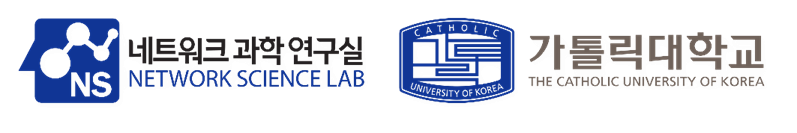

# Week 12: Spatial Temporal Graph Neural Networks

<a target="_blank" href="https://colab.research.google.com/github/NSLab-CUK/Graph-Neural-Networks-Fall-2026/blob/main/W12/SampleCode_12.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

### The idea in two sentences

* Traffic is a signal that lives on a **graph** (sensors connected by roads) and changes over **time**. A jam at one sensor soon reaches the sensors next to it.
* A **spatial-temporal GNN** uses both: a **graph convolution** looks at the *neighbors* of a sensor, a **temporal convolution** looks at its *recent past*.

| | What it means here |
|---|---|
| **Data** | METR-LA: 207 speed sensors on Los Angeles highways, one reading every 5 minutes |
| **Task** | Given the **last hour** of speeds (12 steps), predict the **next hour** (12 steps) for every sensor |
| **Model** | **STGCN** (Yu, Yin, Zhu, IJCAI 2018) |
| **Question** | Does knowing the road graph make the forecast better? |

## 1. Setup

In [1]:
# @title Imports and colors
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import animation
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap

from IPython.display import HTML

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# One color per role, reused in every figure.
COLORS = {"truth": "#0b0b0b", "stgcn": "#2a78d6", "no_graph": "#eb6834", "last": "#9a9a9a"}
MUTED = "#52514e"
SPEED_CMAP = LinearSegmentedColormap.from_list("speed", ["#0d366b", "#256abf", "#6da7ec", "#cde2fb"])  # dark = slow
ERROR_CMAP = LinearSegmentedColormap.from_list("error", ["#fbe3d8", "#f2a07d", "#eb6834", "#8f3311"])  # dark = large error
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "figure.dpi": 110,
                     "animation.embed_limit": 50, "animation.frame_format": "jpeg"})   # jpeg keeps the notebook small
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.11.0+cu128 | device: cuda


## 2. Data: one week of Los Angeles traffic

We download three small CSV files (about 3.5 MB):

* `speed`: a table of shape **[time, sensors]** = [2016, 207]. One week (Thu 1 March to Wed 7 March 2012), in miles per hour.
* `W`: the **road graph**, a 207 × 207 matrix. $W_{ij} = \exp(-d_{ij}^2 / \sigma^2)$, where $d_{ij}$ is the **driving distance** from sensor $i$ to sensor $j$. Far-away pairs are set to 0.
* `xy`: the position of every sensor (only used for drawing).

In [2]:
FILES = {
    "los_speed.csv": "https://raw.githubusercontent.com/lehaifeng/T-GCN/master/data/los_speed.csv",
    "los_adj.csv": "https://raw.githubusercontent.com/lehaifeng/T-GCN/master/data/los_adj.csv",
    "graph_sensor_locations.csv": "https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/graph_sensor_locations.csv",
}
DATA_DIR = Path("data/metr-la")
DATA_DIR.mkdir(parents=True, exist_ok=True)
for name, url in FILES.items():
    if not (DATA_DIR / name).exists():
        urllib.request.urlretrieve(url, DATA_DIR / name)

speed = pd.read_csv(DATA_DIR / "los_speed.csv").values.astype(np.float32)            # [time, sensors]
W = pd.read_csv(DATA_DIR / "los_adj.csv", header=None).values.astype(np.float32)     # [sensors, sensors]
np.fill_diagonal(W, 0)                                                                # no self-loops
xy = pd.read_csv(DATA_DIR / "graph_sensor_locations.csv")[["longitude", "latitude"]].values

DAY = 288                                                                             # 5-minute steps per day
times = pd.date_range("2012-03-01", periods=len(speed), freq="5min")
N = speed.shape[1]
print(f"speed: {speed.shape} = [time, sensors]   from {times[0]} to {times[-1]}")
print(f"graph: {N} sensors, {(W > 0).sum()} directed edges, {(W > 0).sum(1).mean():.1f} neighbors per sensor")

speed: (2016, 207) = [time, sensors]   from 2012-03-01 00:00:00 to 2012-03-07 23:55:00
graph: 207 sensors, 2626 directed edges, 12.7 neighbors per sensor


### 2.1 Space: traffic lives on a road graph

Each dot is a sensor and each gray line an edge of the road graph. **Dark = slow.** At night every road is free; in the rush hours the jams appear as **connected dark stretches**, not as isolated dots.

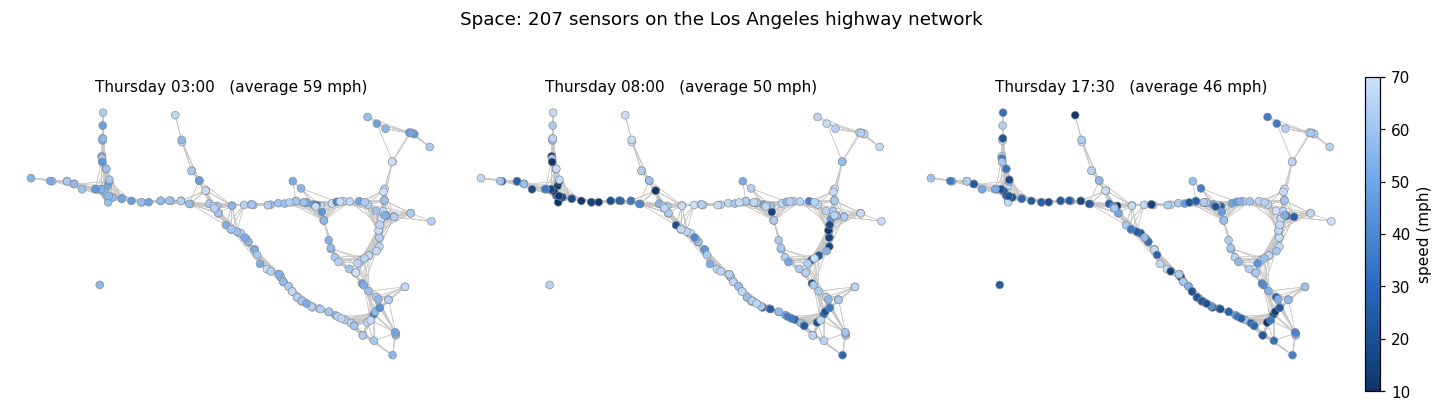

In [3]:
# @title Plot: the road network at three moments of one day
EDGES = np.argwhere(W > 0)

def draw_map(ax, values, title, cmap=SPEED_CMAP, vmin=10, vmax=70, highlight=None):
    """Sensors at their real position, colored by `values`. Returns the scatter (for the colorbar)."""
    ax.add_collection(LineCollection(xy[EDGES], colors="#c9c8c4", linewidths=0.4, zorder=1))
    dots = ax.scatter(*xy.T, c=values, cmap=cmap, vmin=vmin, vmax=vmax, s=26,
                      edgecolors="#8a8985", linewidths=0.4, zorder=2)
    if highlight is not None:
        ax.scatter(*xy[highlight].T, s=120, facecolors="none", edgecolors=COLORS["truth"], linewidths=1.4, zorder=3)
    ax.set_title(title, fontsize=10)
    ax.set(xticks=[], yticks=[], aspect=1.2)
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    return dots

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), constrained_layout=True)
for ax, clock in zip(axes, ["03:00", "08:00", "17:30"]):
    t = times.get_loc(pd.Timestamp(f"2012-03-01 {clock}"))
    dots = draw_map(ax, speed[t], f"Thursday {clock}   (average {speed[t].mean():.0f} mph)")
fig.colorbar(dots, ax=axes, label="speed (mph)", shrink=0.8, pad=0.01)
fig.suptitle("Space: 207 sensors on the Los Angeles highway network")
plt.show()

In [4]:
# @title Helper: animate maps over time (play button + slider)
def animate_maps(maps, curves, clock, title, interval=250):
    """maps:   {panel title: [frames, sensors]}  one map per entry, colored by speed.
    curves: {key in COLORS: (label, [frames])}  network averages, drawn with a moving cursor.
    clock:  the time stamp of every frame."""
    n = len(maps)
    fig, axes = plt.subplots(1, n + 1, figsize=(4.6 * n + 5.2, 3.9), dpi=62, constrained_layout=True,
                             gridspec_kw={"width_ratios": [1] * n + [1.15]})
    dots = [draw_map(ax, values[0], name) for ax, (name, values) in zip(axes, maps.items())]
    fig.colorbar(dots[-1], ax=axes[:n], label="speed (mph)", shrink=0.8, pad=0.01)
    ax = axes[-1]
    for key, (label, values) in curves.items():
        ax.plot(clock, values, color=COLORS[key], lw=2, label=label)
    cursor = ax.axvline(clock[0], color=MUTED, lw=1, ls="--")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
    ax.set(title="average speed of all sensors (mph)", ylim=(30, 70))
    if len(curves) > 1:
        ax.legend(frameon=False, loc="lower left")
    heading = fig.suptitle(f"{title}   {clock[0]:%A %H:%M}")

    def update(k):
        for dot, values in zip(dots, maps.values()):
            dot.set_array(values[k])
        cursor.set_xdata([clock[k], clock[k]])
        heading.set_text(f"{title}   {clock[k]:%A %H:%M}")

    anim = animation.FuncAnimation(fig, update, frames=len(clock), interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode="loop"))

day = slice(0, DAY, 6)                                         # Thursday, one frame every 30 minutes
animate_maps({"speed of every sensor": speed[day]}, {"stgcn": ("measured", speed[day].mean(1))},
             times[day], "Traffic in Los Angeles,")

### 2.2 Time: traffic has a rhythm, and jams travel

* **Left:** one sensor over the whole week. The speed drops every working day at the same hours, and much less on the weekend.
* **Right:** the same sensor and its two closest graph neighbors on one morning. The three curves fall and recover **together, a few minutes apart**. This is the signal a graph model can use.

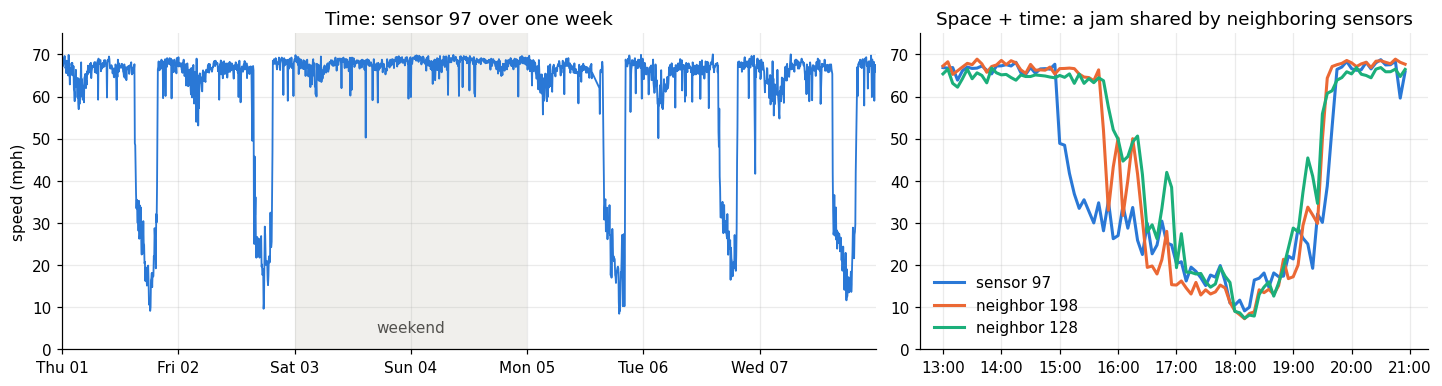

In [5]:
# @title Plot: one sensor over a week, and a jam shared by neighbors
SENSOR = 97                                      # the sensor we follow in this notebook
neighbors = np.argsort(-(W + W.T)[SENSOR])[:2]           # its two closest neighbors in the road graph

fig, (ax_w, ax_n) = plt.subplots(1, 2, figsize=(13, 3.4), constrained_layout=True, gridspec_kw={"width_ratios": [1.6, 1]})

ax_w.axvspan(times[2 * DAY], times[4 * DAY], color="#f0efec", lw=0)
ax_w.text(times[3 * DAY], 4, "weekend", ha="center", color=MUTED)
ax_w.plot(times, speed[:, SENSOR], color=COLORS["stgcn"], lw=1.2)
ax_w.xaxis.set_major_locator(mdates.DayLocator())
ax_w.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
ax_w.set(title=f"Time: sensor {SENSOR} over one week", ylabel="speed (mph)", ylim=(0, 75), xlim=(times[0], times[-1]))

lo, hi = times.get_loc(pd.Timestamp("2012-03-01 13:00")), times.get_loc(pd.Timestamp("2012-03-01 21:00"))
for node, color, name in zip([SENSOR, *neighbors], [COLORS["stgcn"], COLORS["no_graph"], "#1baf7a"],
                             [f"sensor {SENSOR}", f"neighbor {neighbors[0]}", f"neighbor {neighbors[1]}"]):
    ax_n.plot(times[lo:hi], speed[lo:hi, node], color=color, lw=2, label=name)
ax_n.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax_n.set(title="Space + time: a jam shared by neighboring sensors", ylim=(0, 75))
ax_n.legend(frameon=False, loc="lower left")
plt.show()

### 2.3 From one long recording to training examples

We slide a window over the week. Each position gives one example:

* **input** $X$: the last 12 steps (1 hour) of all sensors, shape `[12, 207]`
* **target** $Y$: the next 12 steps (1 hour) of all sensors, shape `[12, 207]`

The split follows time: **train** on Thursday to Monday, **validate** on Tuesday, **test** on Wednesday.

In [6]:
T_IN, T_OUT = 12, 12                                         # 1 hour in, 1 hour out
MEAN, STD = speed[:5 * DAY].mean(), speed[:5 * DAY].std()    # statistics of the training days only

def make_windows(first, last):
    """All (input, target) pairs whose target lies in the steps [first, last)."""
    start = np.arange(max(first - T_IN, 0), last - T_IN - T_OUT + 1)
    x = speed[start[:, None] + np.arange(T_IN)]                       # [examples, T_IN, sensors]
    y = speed[start[:, None] + T_IN + np.arange(T_OUT)]               # [examples, T_OUT, sensors]
    t_y = times[start + T_IN]                                         # clock time of the first target step
    return torch.tensor((x - MEAN) / STD).to(DEVICE), torch.tensor(y).to(DEVICE), t_y

x_train, y_train, _ = make_windows(0, 5 * DAY)                # Thu - Mon
x_val, y_val, _ = make_windows(5 * DAY, 6 * DAY)              # Tue
x_test, y_test, t_test = make_windows(6 * DAY, 7 * DAY)       # Wed
print(f"train {tuple(x_train.shape)}   val {tuple(x_val.shape)}   test {tuple(x_test.shape)}   = [examples, steps, sensors]")

train (1417, 12, 207)   val (277, 12, 207)   test (277, 12, 207)   = [examples, steps, sensors]


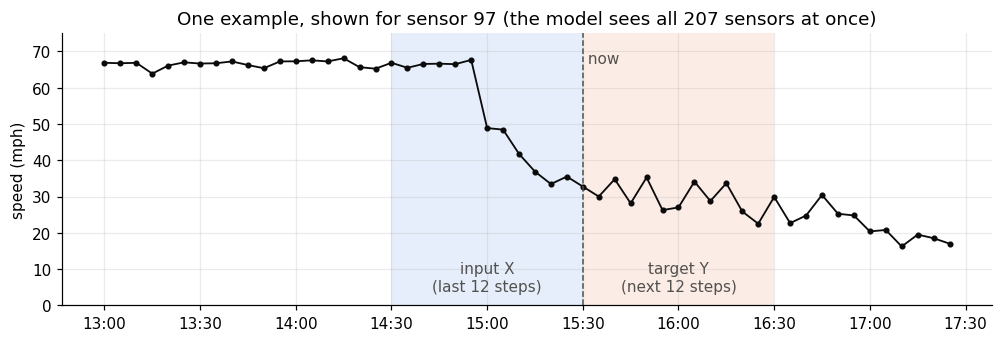

In [7]:
# @title Plot: one training example
now = times.get_loc(pd.Timestamp("2012-03-01 15:30"))
span = slice(now - 30, now + 24)

fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
ax.axvspan(times[now - T_IN], times[now], color=COLORS["stgcn"], alpha=0.12, lw=0)
ax.axvspan(times[now], times[now + T_OUT], color=COLORS["no_graph"], alpha=0.12, lw=0)
ax.plot(times[span], speed[span, SENSOR], color=COLORS["truth"], lw=1.2, marker="o", ms=3)
ax.axvline(times[now], color=MUTED, lw=1, ls="--")
ax.text(times[now - 6], 4, "input X\n(last 12 steps)", ha="center", color=MUTED)
ax.text(times[now + 6], 4, "target Y\n(next 12 steps)", ha="center", color=MUTED)
ax.text(times[now], 70, " now", va="top", color=MUTED)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set(title=f"One example, shown for sensor {SENSOR} (the model sees all 207 sensors at once)",
       ylabel="speed (mph)", ylim=(0, 75))
plt.show()

## 3. Model: STGCN

The input is a small "video" of the graph: `[time, sensors]`. STGCN stacks two **ST-Conv blocks** and an output layer. Each block is a sandwich:

$$\underbrace{\text{temporal gated conv}}_{\text{each sensor: its recent past}} \;\rightarrow\; \underbrace{\text{spatial graph conv}}_{\text{each step: its road neighbors}} \;\rightarrow\; \underbrace{\text{temporal gated conv}}_{\text{each sensor: its recent past}}$$

**Temporal gated convolution.** A 1-D convolution over $K_t = 3$ consecutive time steps of one sensor. It produces two halves $P$ and $Q$; $Q$ acts as a **gate** that decides how much of $P$ passes (a *gated linear unit*). No recurrence, so all time steps are computed in parallel.

$$\text{output} = (P + \text{input}) \odot \sigma(Q)$$

**Spatial graph convolution.** At every time step, a Chebyshev graph convolution of order $K_s = 3$ mixes each sensor with its neighborhood. $T_k$ are Chebyshev polynomials of the scaled graph Laplacian $\tilde L$:

$$H' = \text{ReLU}\Big(\sum_{k=0}^{K_s-1} T_k(\tilde L)\, H\, \Theta_k + H\Big), \qquad T_0 = I \;(\text{the sensor itself}), \quad T_1 = \tilde L \;(\text{1-hop neighbors}), \quad T_2 = 2\tilde L^2 - I \;(\text{2-hop neighbors})$$

```
X [12 steps x 207 sensors] -> ST-Conv block -> ST-Conv block -> output layer -> Y [12 steps x 207 sensors]
channels:                1 ->  32 -> 32 -> 64  ->  32 -> 32 -> 128
time steps left:        12 ->        8         ->        4       ->  1
```

> This is the architecture of the paper and its official code (same layers, same channel sizes). One change for our task: the last layer outputs all **12 future steps at once**, while the paper predicts one step and feeds it back 12 times.

In [8]:
# @title The graph: Chebyshev polynomials of the scaled Laplacian
def chebyshev_polynomials(W, Ks):
    """T_0 ... T_{Ks-1} of the scaled Laplacian, shape [Ks, sensors, sensors]."""
    A = np.maximum(W, W.T)                                       # the paper uses an undirected graph
    d = A.sum(1).clip(min=1e-6)
    L = np.eye(N) - A / np.sqrt(d[:, None] * d[None, :])         # normalized Laplacian
    L = 2 * L / np.linalg.eigvalsh(L).max() - np.eye(N)          # scaled to [-1, 1]
    T = [np.eye(N), L]
    for _ in range(2, Ks):
        T.append(2 * L @ T[-1] - T[-2])                          # T_k = 2 L T_{k-1} - T_{k-2}
    return torch.tensor(np.stack(T[:Ks]), dtype=torch.float32, device=DEVICE)

print(f"Chebyshev polynomials for Ks = 3: {tuple(chebyshev_polynomials(W, 3).shape)}")

Chebyshev polynomials for Ks = 3: (3, 207, 207)


In [9]:
# All tensors inside the model are [batch, channels, sensors, time].

class Align(nn.Module):
    """Make the input fit the output channels, so it can be added as a residual connection."""
    def __init__(self, c_in, c_out):
        super().__init__()
        self.c_in, self.c_out = c_in, c_out
        self.conv = nn.Conv2d(c_in, c_out, kernel_size=1) if c_in > c_out else None

    def forward(self, x):
        if self.c_in > self.c_out:
            return self.conv(x)
        return F.pad(x, (0, 0, 0, 0, 0, self.c_out - self.c_in))      # fill the missing channels with zeros

class TemporalConv(nn.Module):
    """1-D convolution over Kt time steps of ONE sensor (time: T -> T - Kt + 1)."""
    def __init__(self, c_in, c_out, Kt, act="glu"):
        super().__init__()
        self.Kt, self.act = Kt, act
        self.align = Align(c_in, c_out)
        self.conv = nn.Conv2d(c_in, 2 * c_out if act == "glu" else c_out, kernel_size=(1, Kt))

    def forward(self, x):
        residual = self.align(x)[..., self.Kt - 1:]
        h = self.conv(x)
        if self.act == "glu":                                         # gated linear unit
            p, q = h.chunk(2, dim=1)
            return (p + residual) * torch.sigmoid(q)
        if self.act == "sigmoid":
            return torch.sigmoid(h)
        return F.relu(h + residual)

class SpatialConv(nn.Module):
    """Chebyshev graph convolution at every time step (time is unchanged)."""
    def __init__(self, c, cheb):
        super().__init__()
        self.cheb = cheb                                              # [Ks, sensors, sensors]
        self.theta = nn.Conv2d(len(cheb) * c, c, kernel_size=1)       # the weights Theta_k

    def forward(self, x):
        hops = torch.einsum("kij,bcjt->bkcit", self.cheb, x)          # T_k H for every k
        return F.relu(self.theta(hops.flatten(1, 2)) + x)

class LayerNorm(nn.Module):
    """Layer normalization over [sensors, channels], as in the paper."""
    def __init__(self, c):
        super().__init__()
        self.norm = nn.LayerNorm([N, c])

    def forward(self, x):
        return self.norm(x.permute(0, 3, 2, 1)).permute(0, 3, 2, 1)

class STConvBlock(nn.Module):
    """temporal gated conv -> spatial graph conv -> temporal conv -> layer norm -> dropout."""
    def __init__(self, c_in, c_mid, c_out, cheb, Kt, dropout):
        super().__init__()
        self.layers = nn.Sequential(TemporalConv(c_in, c_mid, Kt, "glu"), SpatialConv(c_mid, cheb),
                                    TemporalConv(c_mid, c_out, Kt, "relu"), LayerNorm(c_out), nn.Dropout(dropout))

    def forward(self, x):
        return self.layers(x)

class STGCN(nn.Module):
    def __init__(self, Ks=3, Kt=3, dropout=0.2):
        super().__init__()
        cheb = chebyshev_polynomials(W, Ks)
        self.blocks = nn.Sequential(STConvBlock(1, 32, 64, cheb, Kt, dropout),
                                    STConvBlock(64, 32, 128, cheb, Kt, dropout))
        steps_left = T_IN - 4 * (Kt - 1)                              # every temporal conv removes Kt - 1 steps
        self.output = nn.Sequential(TemporalConv(128, 128, steps_left, "glu"), LayerNorm(128),
                                    TemporalConv(128, 128, 1, "sigmoid"), nn.Conv2d(128, T_OUT, kernel_size=1))

    def forward(self, x):                                             # x: [batch, T_IN, sensors], normalized
        h = self.blocks(x.transpose(1, 2).unsqueeze(1))               # -> [batch, 128, sensors, 4]
        out = self.output(h).squeeze(-1)                              # -> [batch, T_OUT, sensors]
        return out * STD + MEAN                                       # back to mph

model = STGCN().to(DEVICE)
print(f"output shape: {tuple(model(x_train[:8]).shape)}   parameters: {sum(p.numel() for p in model.parameters()):,}")

output shape: (8, 12, 207)   parameters: 321,388


## 4. Training: with and without the graph

We train the **same model twice**. The only difference is the order $K_s$ of the graph convolution:

* **STGCN** ($K_s = 3$): every sensor sees its 1-hop and 2-hop neighbors in each graph convolution.
* **No graph** ($K_s = 1$): only $T_0 = I$ is left. Every sensor sees just its own past (a purely *temporal* model).

The loss is the mean absolute error (MAE) in mph over all sensors and all 12 future steps. We keep the weights with the best validation error.

In [10]:
def train(Ks, epochs=50):
    torch.manual_seed(SEED)
    model = STGCN(Ks=Ks).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best_val, best_weights = float("inf"), None
    for epoch in range(1, epochs + 1):
        model.train()
        for batch in torch.randperm(len(x_train), device=DEVICE).split(50):
            loss = F.l1_loss(model(x_train[batch]), y_train[batch])
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()
        model.eval()
        with torch.no_grad():
            val = F.l1_loss(model(x_val), y_val).item()
        if val < best_val:
            best_val, best_weights = val, {k: v.clone() for k, v in model.state_dict().items()}
        if epoch % 10 == 0:
            print(f"  epoch {epoch}: train MAE {loss.item():.2f}   val MAE {val:.2f} mph")
    model.load_state_dict(best_weights)
    return model.eval()

print("STGCN (road graph, Ks = 3)")
stgcn = train(Ks=3)
print("No graph (Ks = 1)")
no_graph = train(Ks=1)

STGCN (road graph, Ks = 3)


  epoch 10: train MAE 2.94   val MAE 3.46 mph


  epoch 20: train MAE 4.32   val MAE 3.35 mph


  epoch 30: train MAE 2.74   val MAE 3.32 mph


  epoch 40: train MAE 3.09   val MAE 3.30 mph


  epoch 50: train MAE 2.66   val MAE 3.30 mph
No graph (Ks = 1)


  epoch 10: train MAE 3.04   val MAE 3.59 mph


  epoch 20: train MAE 4.56   val MAE 3.44 mph


  epoch 30: train MAE 2.91   val MAE 3.41 mph


  epoch 40: train MAE 3.25   val MAE 3.39 mph


  epoch 50: train MAE 2.80   val MAE 3.39 mph


## 5. Results on the unseen day (Wednesday)

A third, trivial forecast gives us a reference: **"nothing changes"**, i.e. repeat the last measured speed for the whole next hour.

In [11]:
with torch.no_grad():
    predictions = {
        "stgcn": stgcn(x_test).cpu().numpy(),
        "no_graph": no_graph(x_test).cpu().numpy(),
        "last": (x_test[:, -1:, :] * STD + MEAN).expand(-1, T_OUT, -1).cpu().numpy(),
    }                                                           # each: [examples, T_OUT, sensors]
truth = y_test.cpu().numpy()
NAMES = {"stgcn": "STGCN (road graph)", "no_graph": "No graph", "last": "Nothing changes"}

mae = {k: np.abs(p - truth).mean(axis=(0, 2)) for k, p in predictions.items()}      # MAE per future step
table = pd.DataFrame({NAMES[k]: [m[2], m[5], m[11], m.mean()] for k, m in mae.items()},
                     index=["15 min", "30 min", "60 min", "average"]).T
print("Test MAE in mph (lower is better)")
print(table.round(2).to_string())

Test MAE in mph (lower is better)
                    15 min  30 min  60 min  average
STGCN (road graph)    3.21    3.77    4.74     3.80
No graph              3.25    3.84    4.89     3.89
Nothing changes       3.73    4.56    6.00     4.60


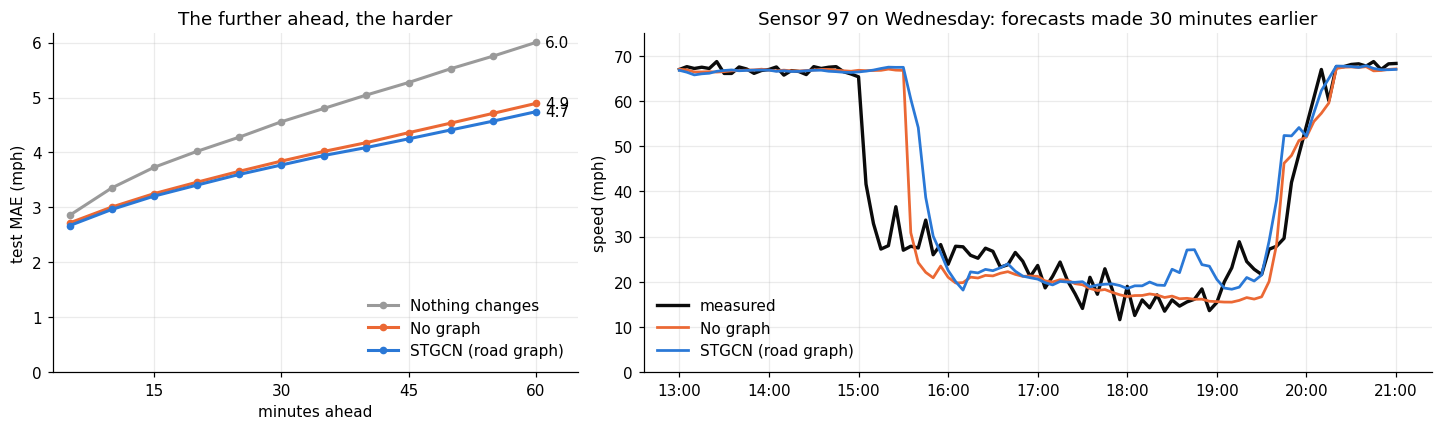

In [12]:
# @title Plot: error by forecast horizon, and one sensor during the evening rush
H = 5                                                           # index 5 = 30 minutes ahead
minutes = 5 * np.arange(1, T_OUT + 1)
fig, (ax_h, ax_s) = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.5]})

for k in ["last", "no_graph", "stgcn"]:
    ax_h.plot(minutes, mae[k], color=COLORS[k], lw=2, marker="o", ms=4, label=NAMES[k])
    ax_h.annotate(f"{mae[k][-1]:.1f}", (minutes[-1], mae[k][-1]), xytext=(6, 0), textcoords="offset points", va="center")
ax_h.set(title="The further ahead, the harder", xlabel="minutes ahead", ylabel="test MAE (mph)", xticks=minutes[2::3],
         xlim=(3, 65), ylim=(0, None))
ax_h.legend(frameon=False, loc="lower right")

t_target = t_test + pd.Timedelta(minutes=5 * H)                 # the clock time each forecast is made FOR
show = (t_target >= pd.Timestamp("2012-03-07 13:00")) & (t_target <= pd.Timestamp("2012-03-07 21:00"))
ax_s.plot(t_target[show], truth[show, H, SENSOR], color=COLORS["truth"], lw=2.2, label="measured")
for k in ["no_graph", "stgcn"]:
    ax_s.plot(t_target[show], predictions[k][show, H, SENSOR], color=COLORS[k], lw=1.8, label=NAMES[k])
ax_s.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax_s.set(title=f"Sensor {SENSOR} on Wednesday: forecasts made 30 minutes earlier", ylabel="speed (mph)", ylim=(0, 75))
ax_s.legend(frameon=False, loc="lower left")
plt.show()

* **Left:** both learned models beat "nothing changes" at every horizon. The road graph adds a small gain everywhere, and the gain **grows with the horizon** (from about 0.04 mph at 5 minutes to about 0.15 mph at 60 minutes).
* **Right:** an honest look at one sensor. Around 15:00 the speed collapses within minutes and both forecasts react about **30 minutes late**: the past hour gave no warning. Inside the jam the two models stay close, and on this sensor the model without a graph is even slightly more accurate. The gain of the graph is an **average over 207 sensors**, not a promise for each one.

In [13]:
frames = slice(1, None, 6)                                     # one frame every 30 minutes
animate_maps({"measured": truth[frames, H], "STGCN forecast (30 min ahead)": predictions["stgcn"][frames, H]},
             {"truth": ("measured", truth[frames, H].mean(1)),
              "stgcn": ("STGCN forecast", predictions["stgcn"][frames, H].mean(1))},
             t_target[frames], "Measured vs forecast,")

The same comparison frozen at the **slowest moment** of the day, with the error of every sensor.

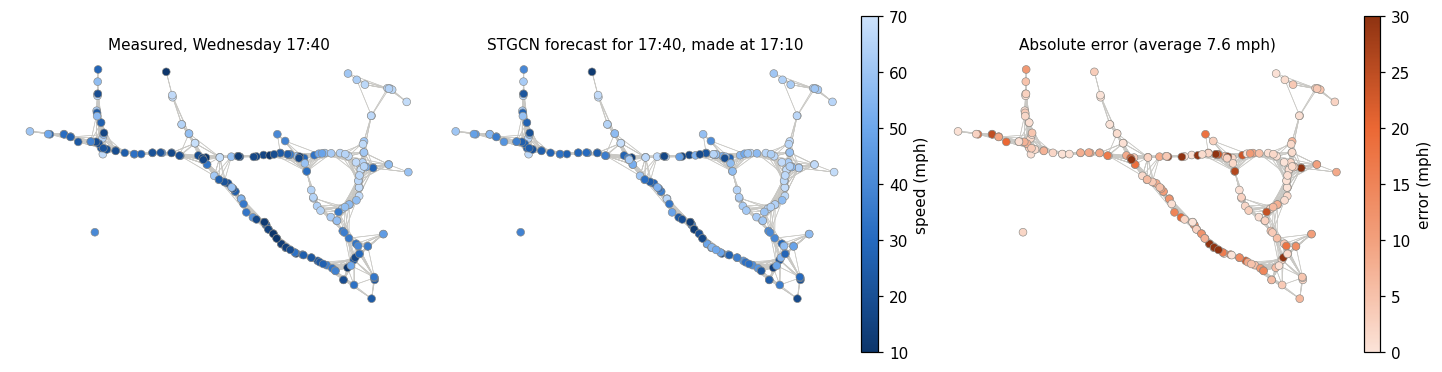

In [14]:
# @title Plot: measured vs predicted traffic on the map
k = truth[:, H, :].mean(1).argmin()                             # the most congested moment of the test day
clock, clock_before = t_target[k].strftime("%H:%M"), (t_target[k] - pd.Timedelta(minutes=30)).strftime("%H:%M")
error = np.abs(predictions["stgcn"][k, H] - truth[k, H])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), constrained_layout=True)
dots = draw_map(axes[0], truth[k, H], f"Measured, Wednesday {clock}")
draw_map(axes[1], predictions["stgcn"][k, H], f"STGCN forecast for {clock}, made at {clock_before}")
fig.colorbar(dots, ax=axes[:2], label="speed (mph)", shrink=0.8, pad=0.01)
dots = draw_map(axes[2], error, f"Absolute error (average {error.mean():.1f} mph)", cmap=ERROR_CMAP, vmin=0, vmax=30)
fig.colorbar(dots, ax=axes[2], label="error (mph)", shrink=0.8, pad=0.02)
plt.show()


**References**

* Yu, Yin, Zhu. *Spatio-Temporal Graph Convolutional Networks: A Deep Learning Framework for Traffic Forecasting.* IJCAI 2018.
* Li, Yu, Shahabi, Liu. *Diffusion Convolutional Recurrent Neural Network: Data-Driven Traffic Forecasting.* ICLR 2018 (METR-LA and the road graph).
* Zhao et al. *T-GCN: A Temporal Graph Convolutional Network for Traffic Prediction.* IEEE T-ITS 2020 (the one-week subset used here).